# Какую метрику использовать для Bank Marketing?

Банк обзванивает клиентов и предлагает оформить депозит. Нам нужно предсказать: **оформит клиент депозит (`yes`) или нет (`no`)**

Клиентов, которые говорят `yes`, очень мало - всего **11.27%**. Остальные 88.73% - это `no` - **дисбаланс классов**

## Что мы сделаем с данными
1. Удалим дубликаты
2. Удалим колонку `duration` - leak
3. Колонку `pdays` заменим на **бинарный признак `was_contacted`**:
   - `1` -клиента раньше уже контактировали
   - `0` - клиента никогда не контактировали
4. Остальные признаки оставим как есть (пока что)

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve, roc_curve,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42
DATA_PATH = 'bank-additional-full.csv'

## Загружаем данные и делаем простую обработку

- Создаём бинарную целевую переменную `y_bin`: `1` = `yes`, `0` = `no`
- Удаляем дубликаты
- Удаляем `duration` - это утечка
- Заменяем `pdays` на `was_contacted` (1, если `pdays != 999`, иначе 0), а сам `pdays` удаляем

In [3]:
df = pd.read_csv(DATA_PATH, sep=';')
print(f'Исходный размер: {df.shape[0]} строк × {df.shape[1]} колонок')

df['y_bin'] = (df['y'] == 'yes').astype(int)

df = df.drop_duplicates().reset_index(drop=True)
print(f'После удаления дубликатов: {df.shape[0]} строк')

df = df.drop(columns=['duration'])

df['was_contacted'] = (df['pdays'] != 999).astype(int)
df = df.drop(columns=['pdays'])

print(f'После обработки: {df.shape[0]} строк × {df.shape[1]} колонок')
print(f'\nprevalence (доля "yes"): {df["y_bin"].mean():.4f}')
print(f'Доля контактировавших: {df["was_contacted"].mean():.4f}')

Исходный размер: 41188 строк × 21 колонок
После удаления дубликатов: 41176 строк
После обработки: 41176 строк × 21 колонок

prevalence (доля "yes"): 0.1127
Доля контактировавших: 0.0368


### Вывод

- Исходный датасет содержал **41 188 строк**. После удаления 12 дубликатов осталось **41 176 строк**
- **`prevalence` (доля `yes`)** - около **11.27%**. Это и есть дисбаланс
- **Доля контактировавших** - около **3.68%**. То есть подавляющее большинство клиентов (96.32%) никогда не контактировали раньше. Бинарный `was_contacted` сохранит эту информацию, а числовой `pdays = 999` создавал бы ложный выброс

## Смотрим на дисбаланс классов

Строим две диаграммы: абсолютные значения классов (`no` / `yes`) и их доли в процентах

При сильном дисбалансе модель, которая всегда говорит `no`, будет иметь **высокую Accuracy**, но окажется бесполезной - она не найдёт ни одного клиента, готового оформить депозит

no  =  36537  (88.7337%)
yes =   4639  (11.2663%)

prevalence = 0.1127


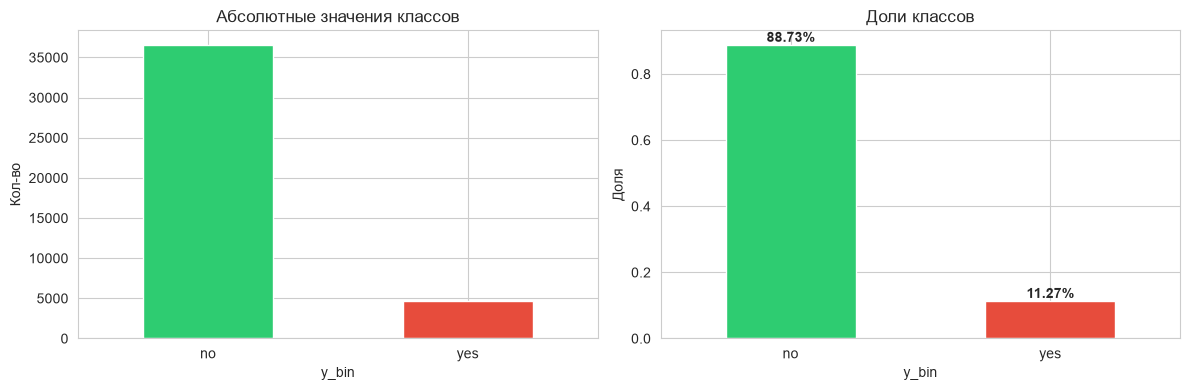

In [4]:
counts = df['y_bin'].value_counts().sort_index()
pct = df['y_bin'].value_counts(normalize=True).sort_index()
prevalence = float(pct.loc[1])

print(f'no  = {counts.loc[0]:>6d}  ({pct.loc[0]:.4%})')
print(f'yes = {counts.loc[1]:>6d}  ({pct.loc[1]:.4%})')
print(f'\nprevalence = {prevalence:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=ax[0], color=['#2ecc71', '#e74c3c'])
ax[0].set_title('Абсолютные значения классов')
ax[0].set_ylabel('Кол-во')
ax[0].set_xticklabels(['no', 'yes'], rotation=0)

pct.plot.bar(ax=ax[1], color=['#2ecc71', '#e74c3c'])
ax[1].set_title('Доли классов')
ax[1].set_ylabel('Доля')
ax[1].set_xticklabels(['no', 'yes'], rotation=0)
for i, v in enumerate(pct.values):
    ax[1].text(i, v + 0.01, f'{v:.2%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Вывод

На диаграммах видно:
- **`no`** - 36 000+- строк (**88.73%**)
- **`yes`** - 4 700+- строк (**11.27%**)

Класс `yes` - это меньшинство. Модель, которая всегда предсказывает `no`, будет права в 88.73% случаев. Если мы будем оценивать модель по **Accuracy**, она покажет "хороший" результат (около 0.887), но по факту не найдёт ни одного клиента. Поэтому **Accuracy нельзя использовать как основную метрику** - она не отражает способность модели находить `yes`

## Метрики
- **Accuracy** = (TP + TN) / всё. "Сколько раз модель угадала". Обманывает при дисбалансе
- **Precision** = TP / (TP + FP). "Из тех, кого модель назвала клиентом, сколько реально оформили депозит"
- **Recall** = TP / (TP + FN). "Из всех реальных клиентов, сколько модель нашла"
- **F1** = 2 × Precision × Recall / (Precision + Recall). "Среднее между Precision и Recall", но симметричное
- **ROC-AUC** — "как хорошо модель разделяет классы по всем порогам". Но **FPR = FP / (FP + TN)** - при огромном TN (36 000) FPR всегда маленькое, поэтому ROC-AUC "сглаживает" разницу между моделями
- **PR-AUC** (`average_precision`) - "качество на положительном классе". Игнорирует TN. **Baseline для случайной модели = prevalence = 0.1127**

## Accuracy

Строим **4 "модели"** (симуляция):
1. `random` - просто угадывает
2. `weak` - слабая модель (чуть лучше случайной)
3. `good` - хорошая модель
4. `constant(no)` - модель, которая **всегда говорит `no`**

In [5]:
def simulate_model(quality, n=20000, pos_frac=prevalence, seed=RANDOM_STATE):
    cfg = {
        'random': dict(class_sep=0.1, flip_y=0.08),
        'weak':   dict(class_sep=0.5, flip_y=0.05),
        'good':   dict(class_sep=1.5, flip_y=0.02),
    }[quality]
    X, y = make_classification(
        n_samples=n, n_features=15, n_informative=8, n_redundant=3,
        n_classes=2, weights=[1 - pos_frac, pos_frac],
        class_sep=cfg['class_sep'], flip_y=cfg['flip_y'],
        random_state=seed,
    )
    return X, y

def metric_row(y_true, y_score, name, threshold=0.5):
    y_pred = (y_score >= threshold).astype(int)
    return {
        'model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'PR-AUC': average_precision_score(y_true, y_score),
        'F1@0.5': f1_score(y_true, y_pred, zero_division=0),
        'Precision@0.5': precision_score(y_true, y_pred, zero_division=0),
        'Recall@0.5': recall_score(y_true, y_pred),
    }

rows, scores = [], {}
for q in ['random', 'weak', 'good']:
    X, y = simulate_model(q)
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    m = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xtr, ytr)
    proba = m.predict_proba(Xte)[:, 1]
    rows.append(metric_row(yte, proba, q))
    scores[q] = (yte, proba)

yte_rand, _ = scores['random']
prev_test = float(yte_rand.mean())
rows.append({
    'model': 'constant(no)',
    'Accuracy': 1 - prev_test, 'ROC-AUC': 0.5, 'PR-AUC': prev_test,
    'F1@0.5': 0.0, 'Precision@0.5': 0.0, 'Recall@0.5': 0.0,
})

comparison = pd.DataFrame(rows).set_index('model').round(4)
print('Таблица метрик (симуляция):')
comparison

Таблица метрик (симуляция):


,Accuracy,ROC-AUC,PR-AUC,F1@0.5,Precision@0.5,Recall@0.5
model,,,,,,
random,0.5132,0.5309,0.1503,0.2399,0.1551,0.5299
weak,0.6468,0.6597,0.3334,0.3131,0.2115,0.6030
good,0.8503,0.8684,0.7228,0.5451,0.4335,0.7340
constant(no),0.8550,0.5000,0.1450,0.0000,0.0000,0.0000


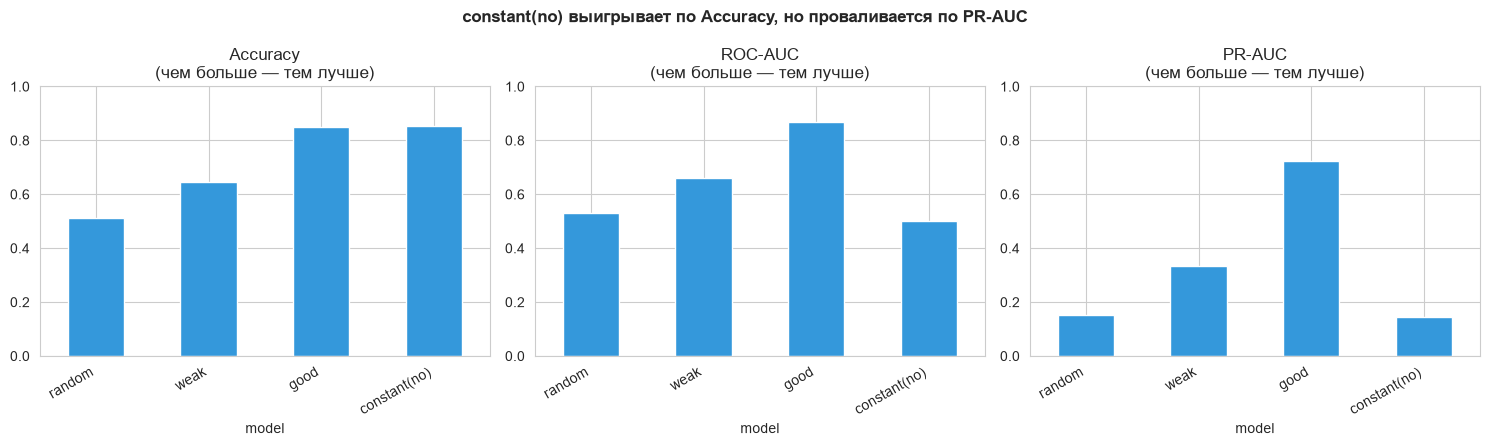

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, ['Accuracy', 'ROC-AUC', 'PR-AUC']):
    comparison[metric].plot.bar(ax=ax, color='#3498db')
    ax.set_title(f'{metric}\n(чем больше — тем лучше)')
    ax.set_ylim(0, 1)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.suptitle('constant(no) выигрывает по Accuracy, но проваливается по PR-AUC',
             fontweight='bold')
plt.tight_layout()
plt.show()

### Вывод

Смотрим на таблицу и графики:

**По Accuracy:**
- `constant(no)` - **0.8550**
- `weak` - **0.6468**
- `random` - **0.5132**

То есть модель-константа (`constant(no)`) **обогнала по Accuracy** более полезную модель `weak`. Если смотреть только на Accuracy, можно выбрать **бесполезную модель**

**По PR-AUC:**
- `random` - **0.1503**
- `weak` - **0.3334**
- `good` - **0.7228**
- `constant(no)` - **0.1450** (это ровно `prevalence` для тестовой выборки)

То есть по PR-AUC `constant(no)` - внизу списка, а `good` - в 5 раз выше `constant(no)`. PR-AUC **упорядочивает модели**

**Итог:** Accuracy обманывает, PR-AUC - нет

## ROC-AUC

Строим две кривые для `weak` и `good`:
- **ROC-кривую** (TPR от FPR)
- **PR-кривую** (Precision от Recall)

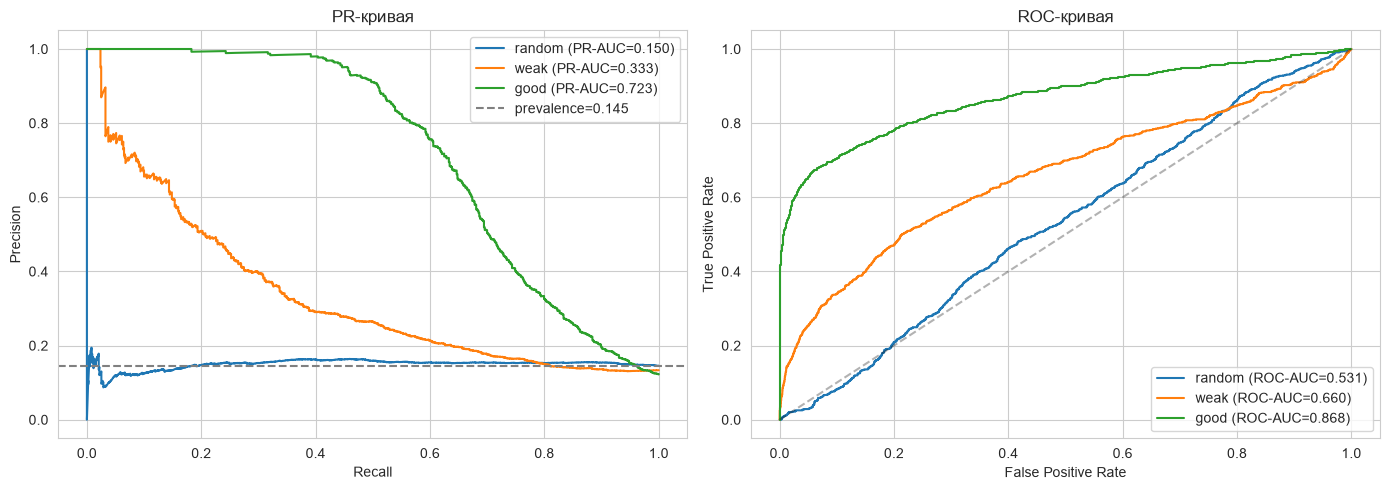

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (yte, proba) in scores.items():
    p, r, _ = precision_recall_curve(yte, proba)
    ap = average_precision_score(yte, proba)
    axes[0].plot(r, p, label=f'{name} (PR-AUC={ap:.3f})')
    fpr, tpr, _ = roc_curve(yte, proba)
    auc = roc_auc_score(yte, proba)
    axes[1].plot(fpr, tpr, label=f'{name} (ROC-AUC={auc:.3f})')

axes[0].axhline(y=prev_test, ls='--', color='gray',
                label=f'prevalence={prev_test:.3f}')
axes[0].set(xlabel='Recall', ylabel='Precision', title='PR-кривая')
axes[0].legend(loc='upper right')

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate',
            title='ROC-кривая')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Вывод

**ROC-кривая:**
`weak` (ROC-AUC = **0.660**) и `good` (ROC-AUC = **0.868**) выглядят "похоже" - обе уходят вправо-вверх. Разница кажется незначительной

**PR-кривая:**
`weak` (PR-AUC = **0.333**) и `good` (PR-AUC = **0.723**) **визуально различаются в 2 раза**. Кривая `good` держится высоко (Precision > 0.8) почти до Recall = 0.6, а `weak` быстро падает.

**Итог:** ROC-AUC сглаживает разницу, PR-AUC нет.

## Проверяем на датасете (Logistic Regression + 5-fold CV)

Обучаем базовую модель **Logistic Regression** с 5-fold кросс-валидацией и считаем все 4 метрики: Accuracy, ROC-AUC, PR-AUC, F1

In [9]:
y = df['y_bin'].values
X = df.drop(columns=['y', 'y_bin'])

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print(f'Признаки: X = {X.shape}, prevalence = {y.mean():.4f}')
print(f'Числовых: {len(num_cols)}, категориальных: {len(cat_cols)}')

pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])
lr = Pipeline([
    ('pre', pre),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'roc_auc': 'roc_auc',
           'pr_auc': 'average_precision', 'f1': 'f1'}

cv_res = {}
for name, sc in scoring.items():
    s = cross_val_score(lr, X, y, cv=cv, scoring=sc, n_jobs=-1)
    cv_res[name] = s
    print(f'  {name:10s}: mean={s.mean():.4f}  std={s.std():.4f}')

Признаки: X = (41176, 19), prevalence = 0.1127
Числовых: 9, категориальных: 10
  accuracy  : mean=0.8271  std=0.0048
  roc_auc   : mean=0.7928  std=0.0142
  pr_auc    : mean=0.4480  std=0.0211
  f1        : mean=0.4503  std=0.0169


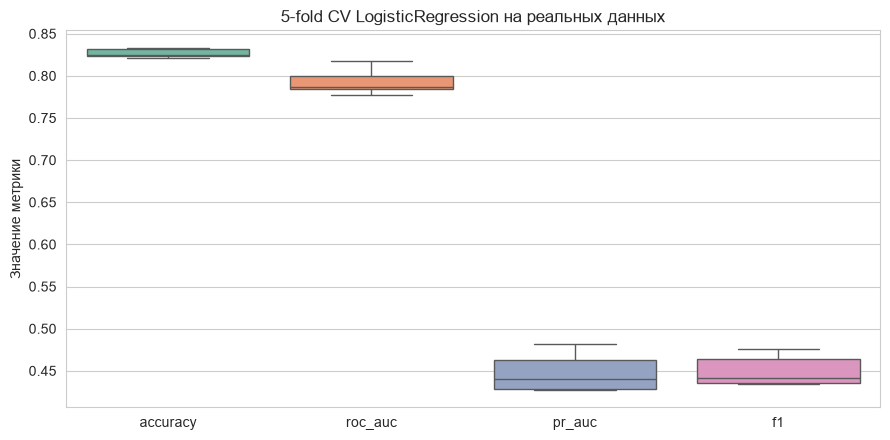

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
df_cv = pd.DataFrame(cv_res)
sns.boxplot(data=df_cv, ax=ax, palette='Set2')
ax.set_title('5-fold CV LogisticRegression на реальных данных')
ax.set_ylabel('Значение метрики')
plt.tight_layout()
plt.show()

Accuracy ~0.83 насыщена, PR-AUC ~0.44 даёт запас для улучшения

### Вывод

- **Accuracy = 0.8273 +- 0.0048** - "высокая", но помним, что `constant(no)` даёт 0.887. То есть Accuracy не различает полезную модель от константы
- **ROC-AUC = 0.7928 +- 0.0142** - "выглядит хорошо", но с учётом сглаживания это не даёт честной картины
- **PR-AUC = 0.4480 +- 0.0211** - это **в 4 раза выше baseline 0.1127**, значит, модель реально учится
- **F1 = 0.4503 +- 0.0169** - среднее. F1 не даёт полной картины, потому что зависит от порога (0.5)

- Accuracy не различает полезную модель и константу
- ROC-AUC сглаживает и даёт оптимистичную картину.
- **PR-AUC - единственная метрика, которая показывает, что модель лучше случайной в 4 раза**, и при этом не обманывает

## Сравниваем метрики

| Метрика | Что измеряет | Плюсы | Минусы | Подходит? |
|---|---|---|---|---|
| **Accuracy** | Доля правильных ответов | Простота | Обманывает при дисбалансе | Нет |
| **ROC-AUC** | Как хорошо модель разделяет классы | Не зависит от порога | Сглаживает разницу на дисбалансе | Только для сравнения |
| **PR-AUC** | Качество на положительном классе | Честная на дисбалансе, baseline = prevalence | Зависит от prevalence | **Да, основная** |
| **F1** | Баланс Precision/Recall | Интуитивно | Симметрична (FP и FN равны) | Для отчёта |
| **Precision** | Точность положительного класса | Важна для экономии | Можно пропустить клиентов | Для отчёта |
| **Recall** | Полнота положительного класса | Важна для бизнеса | Можно звонить всем подряд | Для отчёта |